Import Libraries

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

load Dataset

In [5]:
df = pd.read_csv("FakeNewsNet.csv")

df = df.dropna(subset=['title', 'real'])

X = df['title'].astype(str)
y = df['real'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Apply TF-IDF Vectorization

In [6]:
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=3000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

Train Decision Tree Model

In [7]:
dt_model = DecisionTreeClassifier(
    max_depth=20,
    random_state=42
)

dt_model.fit(X_train_tfidf, y_train)

dt_pred = dt_model.predict(X_test_tfidf)

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 0.8114224137931034

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.38      0.50      1151
           1       0.82      0.95      0.88      3489

    accuracy                           0.81      4640
   macro avg       0.78      0.67      0.69      4640
weighted avg       0.80      0.81      0.79      4640



Train Random Forest Model

In [8]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)

rf_pred = rf_model.predict(X_test_tfidf)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.7920258620689655

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.20      0.32      1151
           1       0.79      0.99      0.88      3489

    accuracy                           0.79      4640
   macro avg       0.82      0.59      0.60      4640
weighted avg       0.80      0.79      0.74      4640



Compare Classification Performance

           Model  Accuracy
0  Decision Tree  0.811422
1  Random Forest  0.792026


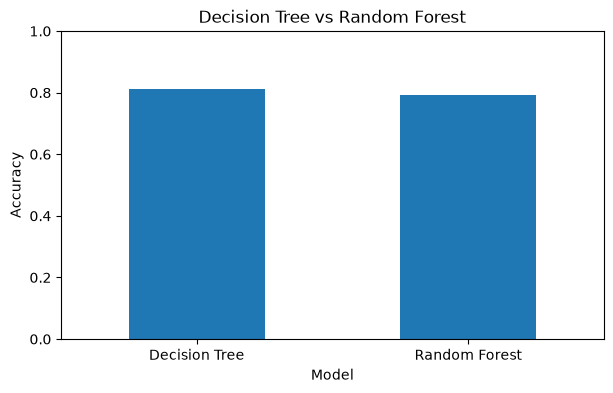

In [9]:
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Accuracy': [
        dt_accuracy,
        rf_accuracy
    ]
})

print(results)

results.plot(
    x='Model',
    y='Accuracy',
    kind='bar',
    legend=False,
    figsize=(7, 4)
)

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

Analyze Feature Importance

In [10]:
feature_names = tfidf.get_feature_names_out()

dt_importance = pd.Series(
    dt_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(15)

rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(15)

print("Decision Tree Important Features:")
print(dt_importance)

print("\nRandom Forest Important Features:")
print(rf_importance)

Decision Tree Important Features:
brad          0.123602
report        0.068504
justin        0.057568
shelton       0.045080
holmes        0.035577
caitlyn       0.035315
kardashian    0.032220
jennifer      0.030904
trump         0.029831
angelina      0.028598
pattinson     0.025528
jenner        0.019780
meghan        0.018430
breaking      0.018004
kanye         0.015178
dtype: float64

Random Forest Important Features:
pitt        0.073749
brad        0.043996
report      0.042680
jolie       0.030174
angelina    0.028951
aniston     0.026279
jennifer    0.023773
justin      0.019903
shelton     0.017257
jenner      0.016199
caitlyn     0.015936
bieber      0.014960
gwen        0.014949
trump       0.014791
holmes      0.014367
dtype: float64


Visualize Feature Importance

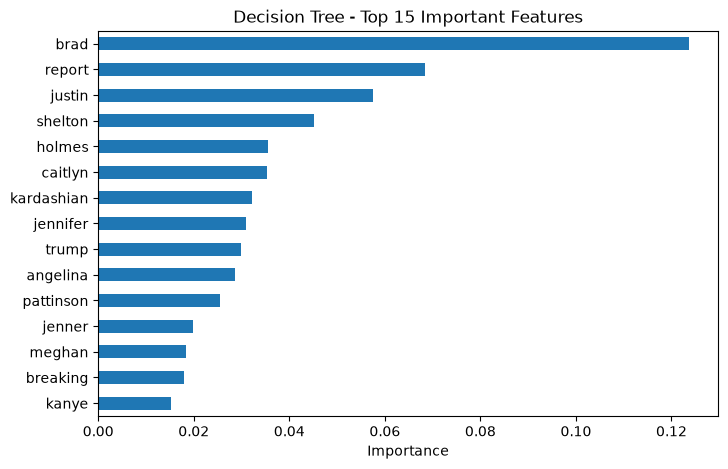

In [11]:
dt_importance.sort_values().plot(
    kind='barh',
    figsize=(8, 5)
)

plt.title("Decision Tree - Top 15 Important Features")
plt.xlabel("Importance")
plt.show()